In [ ]:
import marimo as mo

import itertools

import gseapy
import pertpy.data
import scanpy as sc

import numpy as np
import sklearn as sk
import scipy as sp
import polars as pl

import matplotlib.pyplot as plt
import seaborn as sns

import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader
from ignite.metrics import Accuracy, Loss
from ignite.handlers import EarlyStopping
from ignite.engine import (
    Engine,
    Events,
    create_supervised_trainer,
    create_supervised_evaluator,
)

sns.set_style("darkgrid")

# How does a single-cell autoencoder represent the interferon response?

## Exploratory Analysis

In [ ]:
adata = pertpy.data.kang_2018()
adata.var_names_make_unique()

In [ ]:
df_obs = pl.from_pandas(adata.obs.reset_index())
df_obs.head()

index,nCount_RNA,nFeature_RNA,tsne1,tsne2,label,cluster,cell_type,replicate,nCount_SCT,nFeature_SCT,integrated_snn_res.0.4,seurat_clusters
str,f64,i32,f64,f64,cat,i32,cat,cat,f64,i32,cat,cat
"""AAACATACATTTCC-1""",3017.0,877,-27.640373,14.966629,"""ctrl""",9,"""CD14+ Monocytes""","""patient_1016""",1704.0,711,"""1""","""1"""
"""AAACATACCAGAAA-1""",2481.0,713,-27.493646,28.924885,"""ctrl""",9,"""CD14+ Monocytes""","""patient_1256""",1614.0,662,"""1""","""1"""
"""AAACATACCATGCA-1""",703.0,337,-10.468194,-5.984389,"""ctrl""",3,"""CD4 T cells""","""patient_1488""",908.0,337,"""6""","""6"""
"""AAACATACCTCGCT-1""",3420.0,850,-24.367997,20.429285,"""ctrl""",9,"""CD14+ Monocytes""","""patient_1256""",1738.0,653,"""1""","""1"""
"""AAACATACCTGGTA-1""",3158.0,1111,27.95217,24.159738,"""ctrl""",4,"""Dendritic cells""","""patient_1039""",1857.0,928,"""12""","""12"""


### Is the study design balanced?

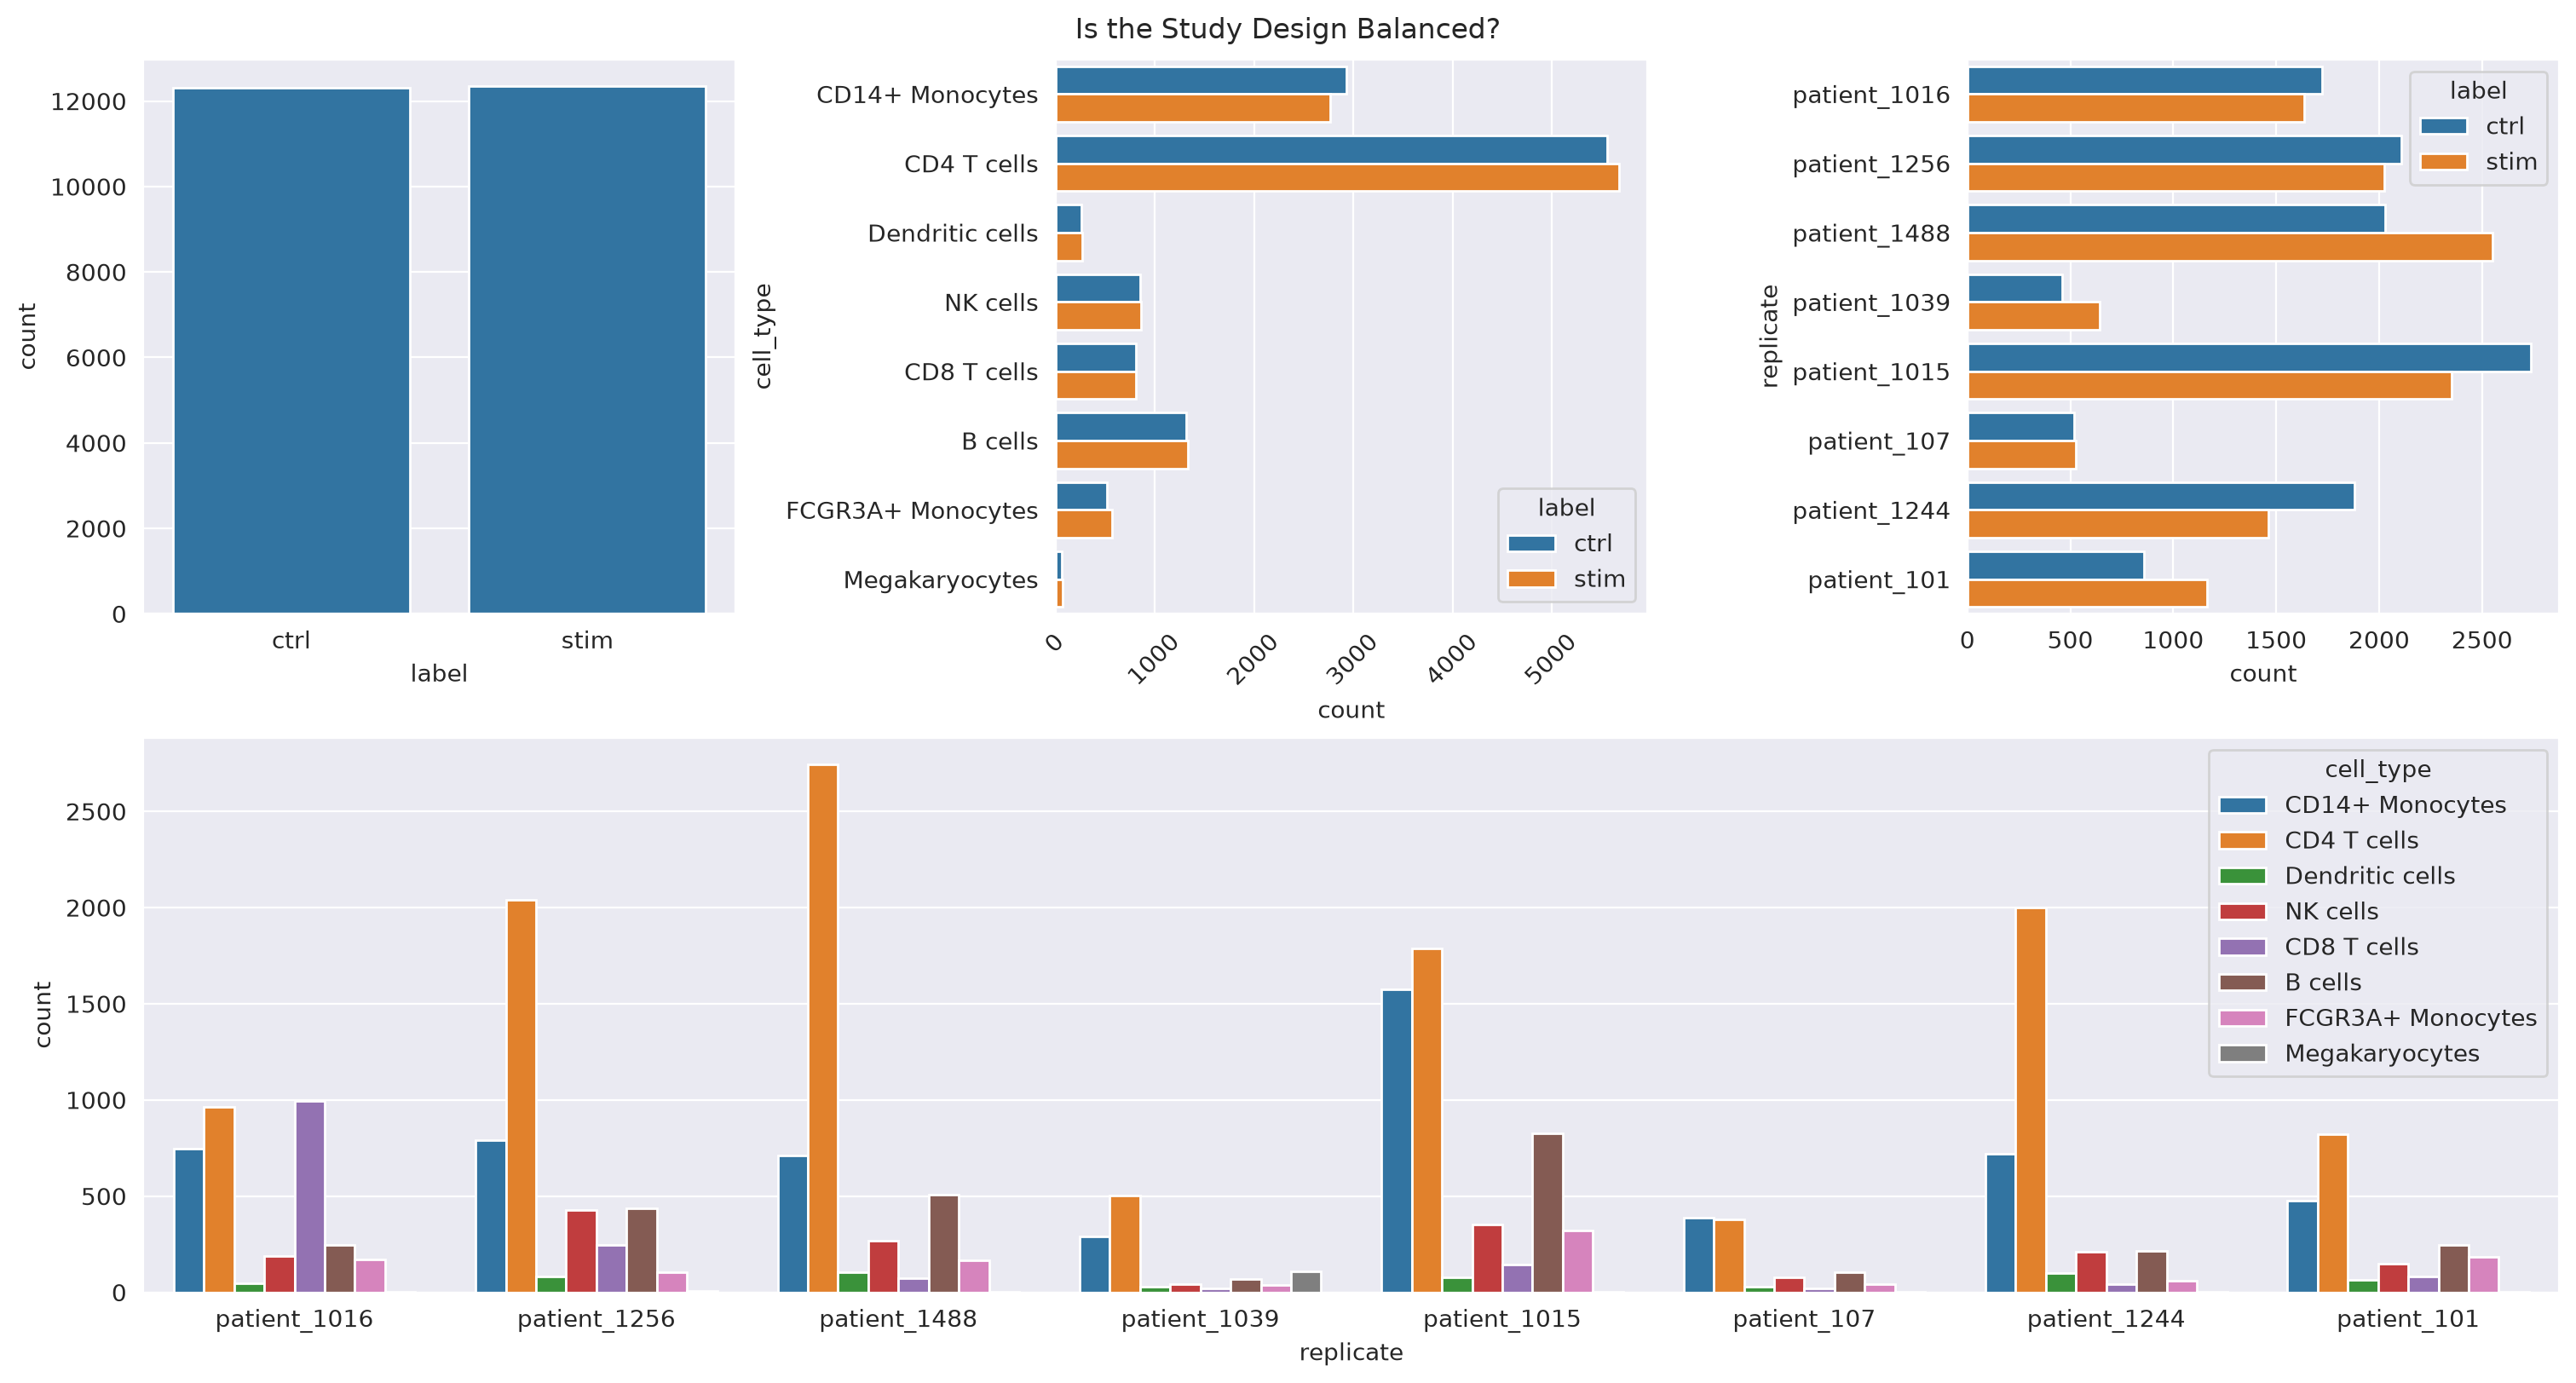

In [ ]:
def _():
    fig, axes = plt.subplot_mosaic(
        """
        abc
        ddd
        """,
        figsize=(15, 8),
        sharex=False,
        sharey=False,
        constrained_layout=True,
    )
    sns.countplot(data=df_obs.to_pandas(), x="label", ax=axes["a"])

    sns.countplot(
        data=df_obs.to_pandas(), y="cell_type", hue="label", ax=axes["b"]
    ).tick_params(axis="x", labelrotation=45)

    sns.countplot(data=df_obs.to_pandas(), y="replicate", hue="label", ax=axes["c"])

    sns.countplot(
        data=df_obs.to_pandas(),
        x="replicate",
        hue="cell_type",
        ax=axes["d"],
    )

    fig.suptitle("Is the Study Design Balanced?")

    return fig

_()

### Quality control

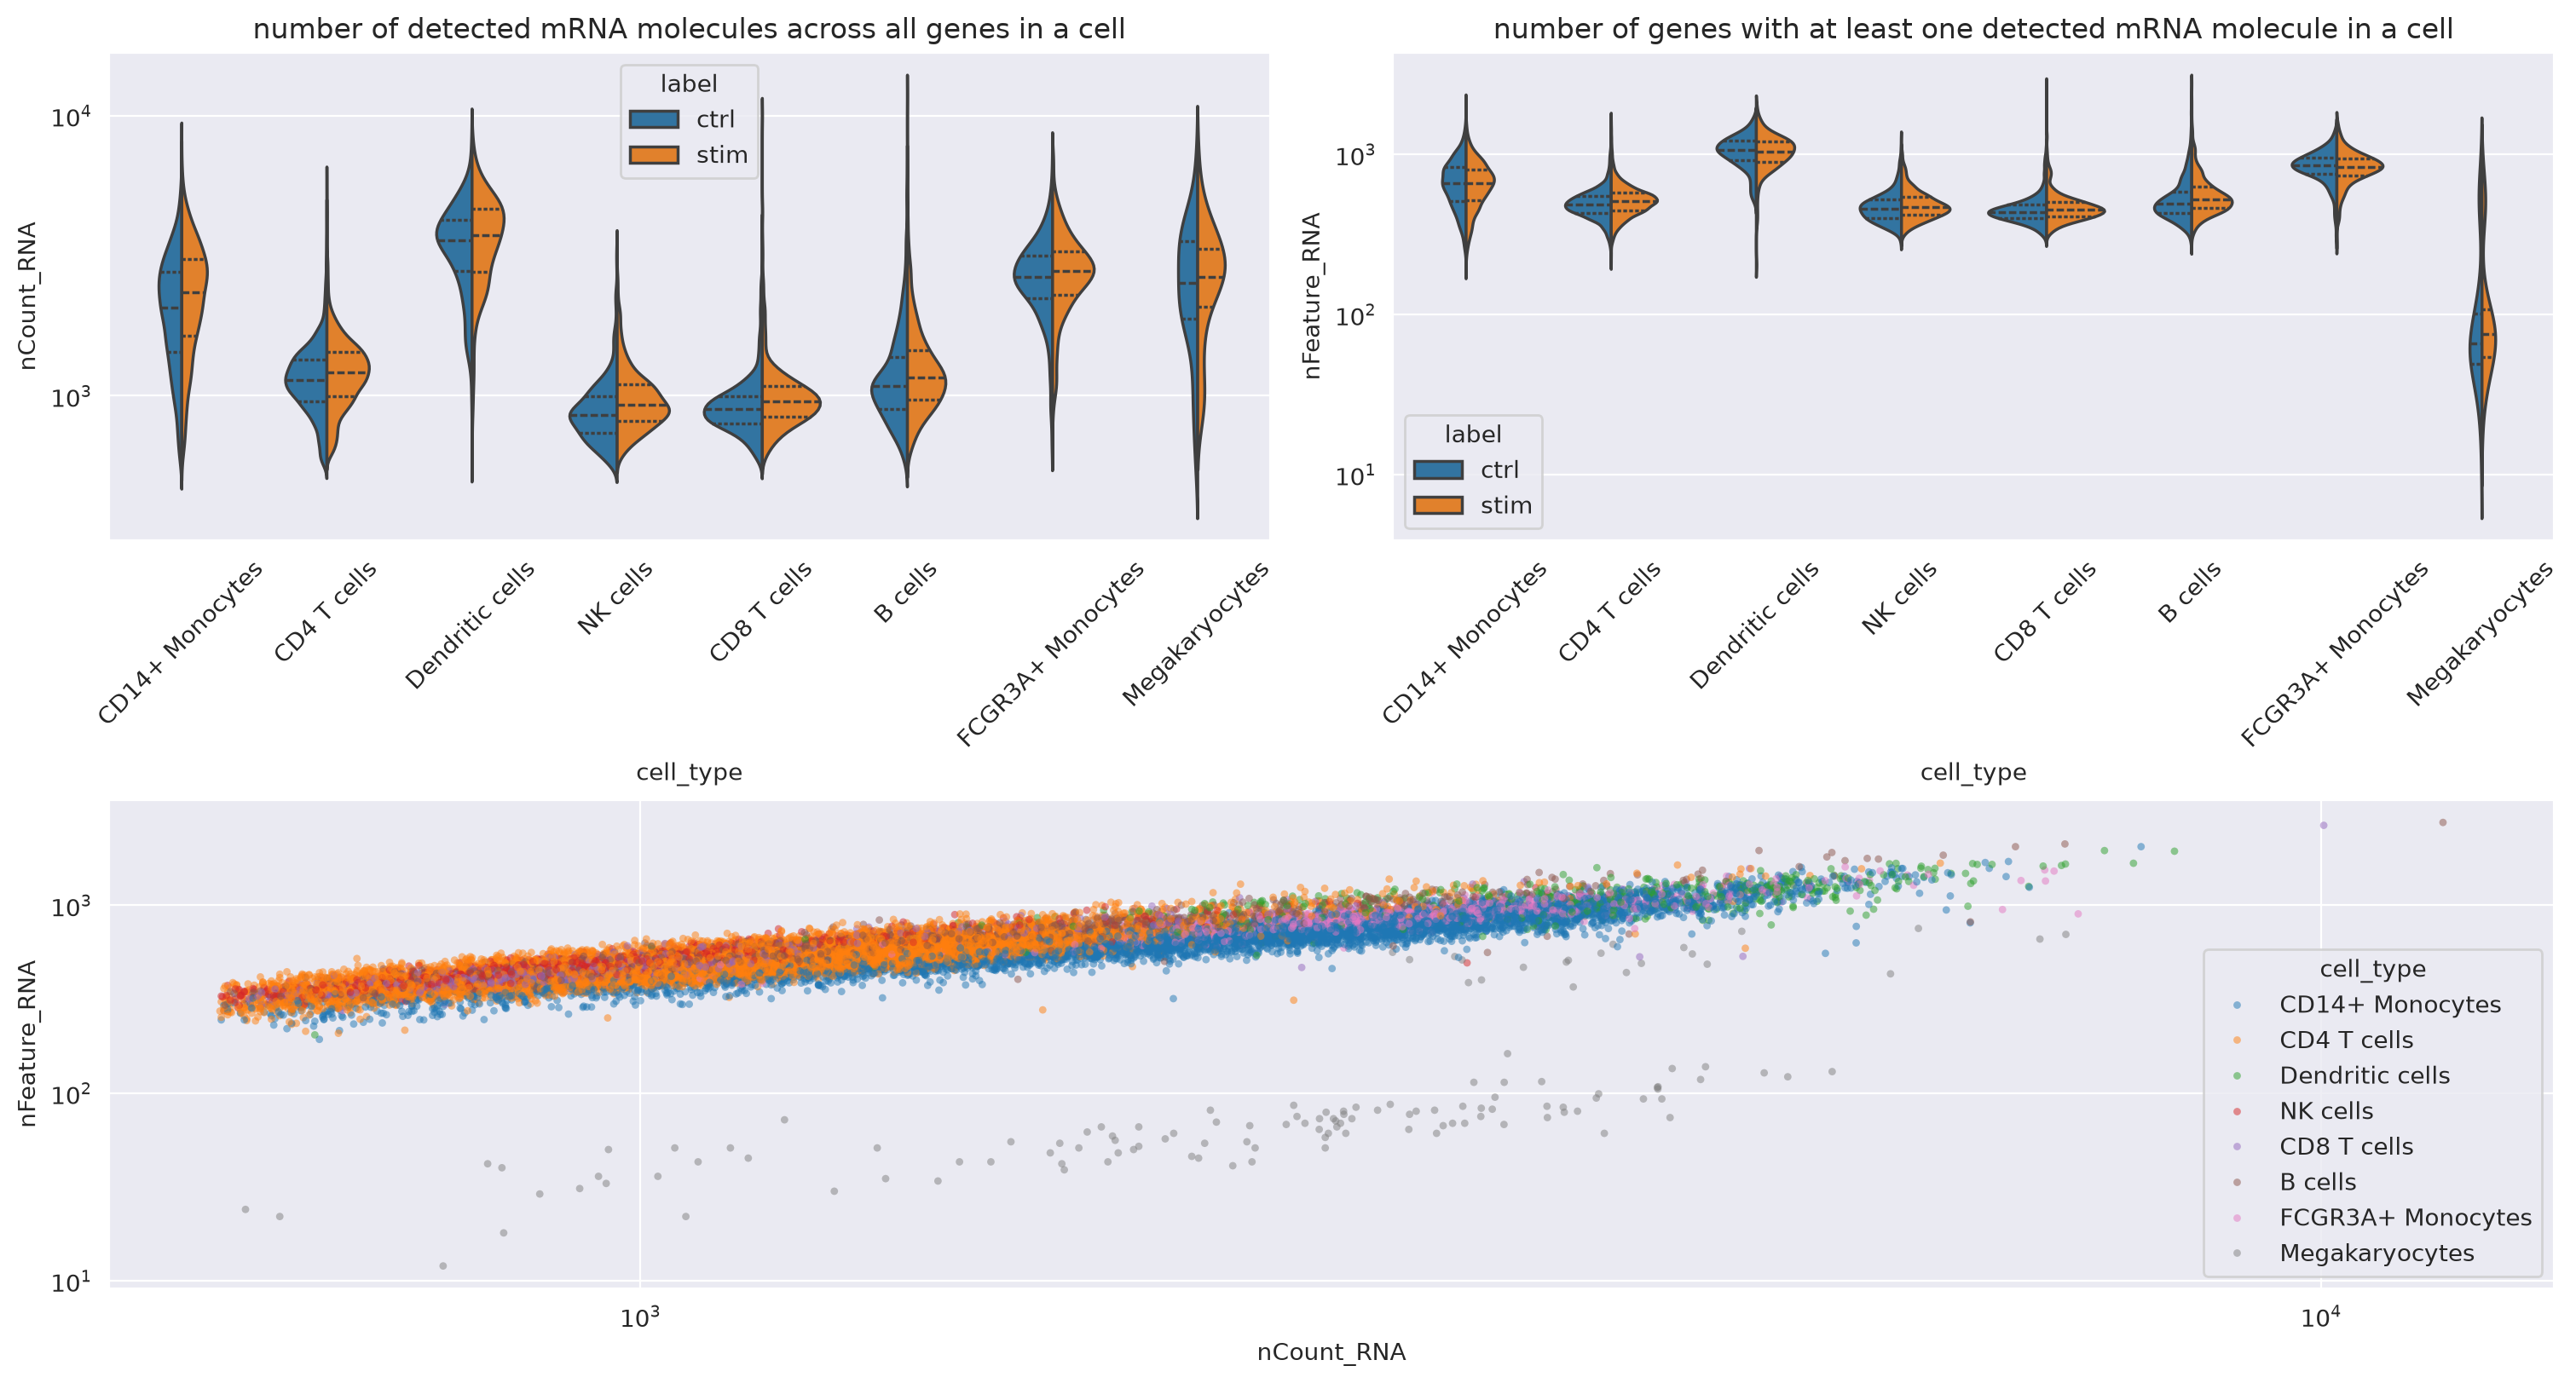

In [ ]:
def _():
    fig, axes = plt.subplot_mosaic(
        """
        ab
        cc
        """,
        figsize=(15, 8),
        sharex=False,
        sharey=False,
        constrained_layout=True,
    )

    sns.violinplot(
        data=df_obs.to_pandas(),
        y="nCount_RNA",
        x="cell_type",
        hue="label",
        log_scale=True,
        split=True,
        inner="quartile",
        ax=axes["a"],
    ).set(title="number of detected mRNA molecules across all genes in a cell")
    axes["a"].tick_params(axis="x", labelrotation=45)

    sns.violinplot(
        data=df_obs.to_pandas(),
        y="nFeature_RNA",
        x="cell_type",
        log_scale=True,
        hue="label",
        split=True,
        inner="quartile",
        ax=axes["b"],
    ).set(title="number of genes with at least one detected mRNA molecule in a cell")
    axes["b"].tick_params(axis="x", labelrotation=45)

    sns.scatterplot(
        data=df_obs.to_pandas(),
        x="nCount_RNA",
        y="nFeature_RNA",
        hue="cell_type",
        s=10,
        linewidth=0,
        alpha=0.5,
        ax=axes["c"],
    )
    axes["c"].set(xscale="log", yscale="log")

    return fig

_()

In [ ]:
def get_gene_contrib(X, gene_names):
    total_molecules_per_cell = np.asarray(X.sum(axis=1)).ravel()
    gene_contrib = sp.sparse.diags(1 / total_molecules_per_cell) @ X
    avg_gene_contrib = np.asarray(gene_contrib.mean(axis=0)).ravel()

    df_avg_gene_contrib = (
        pl.DataFrame(
            {
                "gene": gene_names,
                "avg_pct_per_cell": avg_gene_contrib * 100,
            }
        )
        .sort("avg_pct_per_cell", descending=True)
        .with_columns(pl.col("avg_pct_per_cell").cum_sum().alias("cum_pct"))
    )

    return df_avg_gene_contrib

In [ ]:
df_gc = get_gene_contrib(X=adata.X, gene_names=adata.var_names)
df_gc

gene,avg_pct_per_cell,cum_pct
str,f32,f32
"""MALAT1""",6.560628,6.560628
"""FTH1""",5.111991,11.672619
"""B2M""",3.76519,15.437809
"""TMSB4X""",2.93878,18.376591
"""FTL""",2.098846,20.475435
…,…,…
"""ESPL1""",0.000003,99.999992
"""INSM1""",0.000003,100.0
"""AC002454.1""",0.000003,100.0


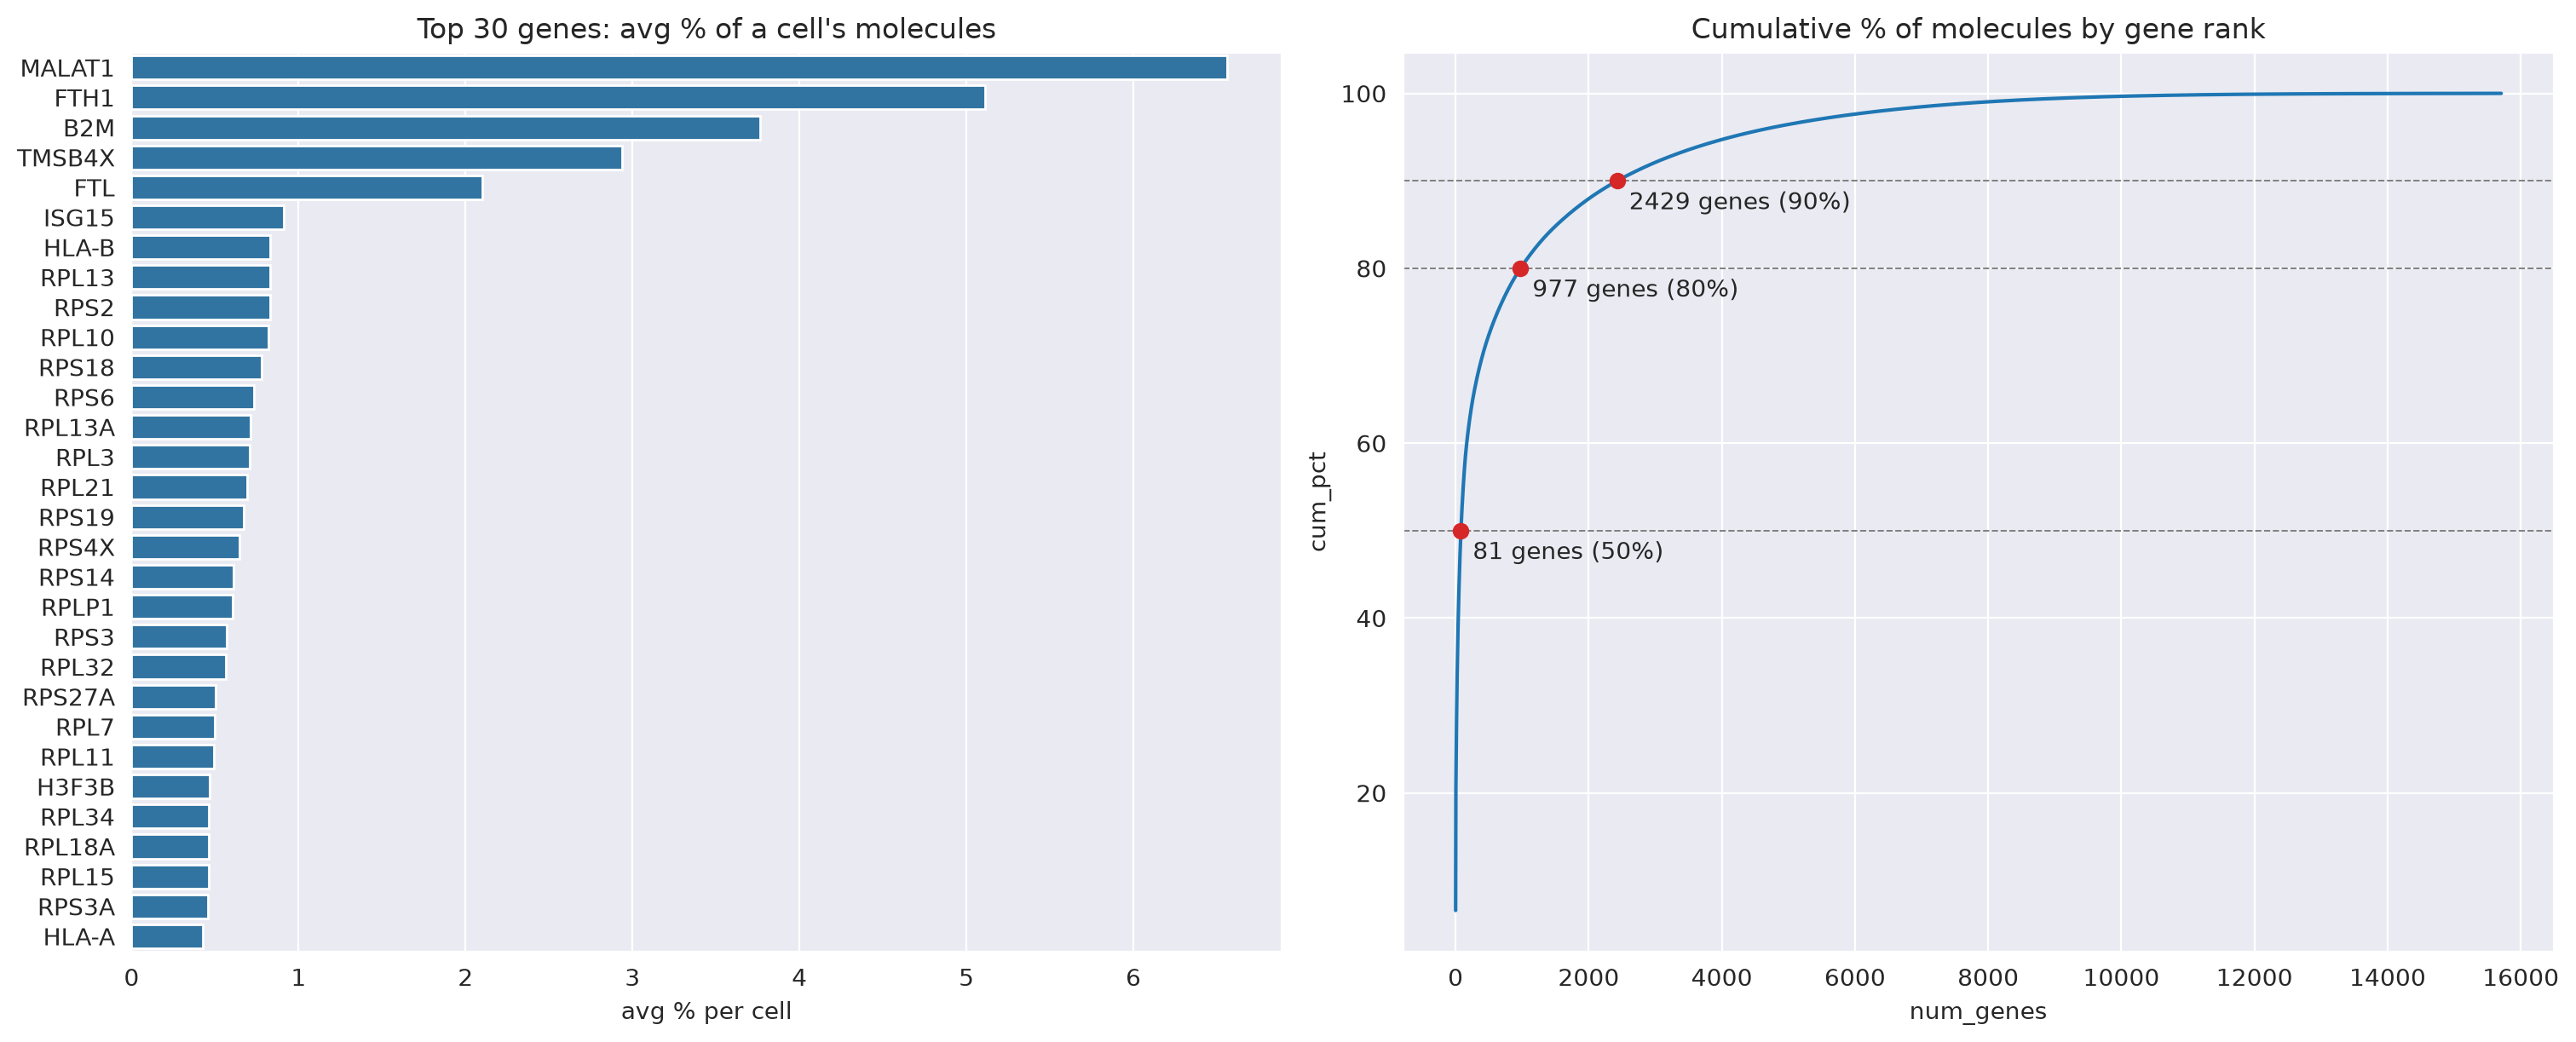

In [ ]:
def _():
    fig, axes = plt.subplot_mosaic(
        """
    ab
    """,
        figsize=(15, 6),
        constrained_layout=True,
    )

    top = df_gc.head(30).to_pandas()

    sns.barplot(data=top, y="gene", x="avg_pct_per_cell", ax=axes["a"]).set(
        title="Top 30 genes: avg % of a cell's molecules",
        xlabel="avg % per cell",
        ylabel="",
    )

    df_cum = df_gc.with_row_index("num_genes", offset=1).to_pandas()
    ax = axes["b"]
    sns.lineplot(data=df_cum, x="num_genes", y="cum_pct", ax=ax).set(
        title="Cumulative % of molecules by gene rank"
    )

    for thr in [50, 80, 90]:
        n = int((df_cum["cum_pct"] < thr).sum()) + 1
        ax.axhline(thr, ls="--", c="grey", lw=0.7)
        ax.plot(n, thr, "o", c="C3")
        ax.annotate(
            f"{n} genes ({thr}%)",
            (n, thr),
            xytext=(5, -12),
            textcoords="offset points",
        )

    return fig

_()

### Interferon Alpha Response genes

In [ ]:
hallmark = gseapy.get_library("MSigDB_Hallmark_2020", organism="Human")
genes_ISG = hallmark["Interferon Alpha Response"]
genes_ISG

In [ ]:
msigdb = gseapy.Msigdb().get_gmt(category="c2.all", dbver="2023.2.Hs")
genes_HKP = msigdb["HSIAO_HOUSEKEEPING_GENES"]
genes_HKP

## Preprocess Data

In [ ]:
ad = adata.copy()
ad.layers["counts"] = ad.X.copy()
sc.pp.filter_genes(ad, min_cells=10)
sc.pp.normalize_total(ad, target_sum=1e4)
sc.pp.log1p(ad)
sc.pp.highly_variable_genes(ad, n_top_genes=2000, batch_key="replicate")

gene_mask = ad.var["highly_variable"] | ad.var_names.isin(genes_ISG + genes_HKP[:10])
ad = ad[:, gene_mask].copy()
print(ad.shape)

/tmp/marimo_10393/__marimo__cell_ROlb_.py:6: FutureWarning: The argument batch_key is deprecated and will be removed in the future. Use `batch` instead, e.g. `batch=A.obs['b']` for `batch_key='b'`.
  sc.pp.highly_variable_genes(ad, n_top_genes=2000, batch_key="replicate")


(24673, 2086)


## Deep Learning

In [ ]:
def make_traintest_replicates(replicates, n_test=1):
    reps = sorted(replicates)
    return [
        {"test": list(test), "train": [r for r in reps if r not in test]}
        for test in itertools.combinations(reps, n_test)
    ]

folds = make_traintest_replicates(replicates=ad.obs["replicate"].unique().tolist(), n_test=1)
train_replicates = folds[0]["train"]
test_replicates = folds[0]["test"]

train_replicates, test_replicates

In [ ]:
replicates = ad.obs["replicate"].astype(str).to_numpy()
trainval_idx = np.where(np.isin(replicates, train_replicates))[0]
test_idx = np.where(np.isin(replicates, test_replicates))[0]

strata = (ad.obs["replicate"].astype(str) + "_" + ad.obs["label"].astype(str)).to_numpy()
train_idx, val_idx = sk.model_selection.train_test_split(
    trainval_idx,
    test_size=0.1,
    random_state=99,
    stratify=strata[trainval_idx],
)

x_all = torch.tensor(ad.X.toarray(), dtype=torch.float32)
x_train = x_all[train_idx]
x_val = x_all[val_idx]
x_test = x_all[test_idx]

loader_train = DataLoader(TensorDataset(x_train), batch_size=1024, shuffle=True)
loader_val = DataLoader(TensorDataset(x_val), batch_size=1024, shuffle=False)
loader_test = DataLoader(TensorDataset(x_test), batch_size=1024, shuffle=False)

print(
    f"train: {len(train_idx)} cells | val: {len(val_idx)} cells | test: {len(test_idx)} cells"
)

print(f"train/val donors: {sorted(train_replicates)}\ntest donors: {sorted(test_replicates)}")

train: 20384 cells | val: 2265 cells | test: 2024 cells
train/val donors: ['patient_1015', 'patient_1016', 'patient_1039', 'patient_107', 'patient_1244', 'patient_1256', 'patient_1488']
test donors: ['patient_101']


In [ ]:
class AutoEncoder(nn.Module):
    def __init__(self, n_genes, n_hidden_1, n_hidden_2, n_latent):
        super().__init__()
        self.enc = nn.Sequential(
            nn.Linear(n_genes, n_hidden_1),
            nn.ReLU(),
            nn.Linear(n_hidden_1, n_hidden_2),
            nn.ReLU(),
            nn.Linear(n_hidden_2, n_latent),
        )
        self.dec = nn.Sequential(
            nn.Linear(n_latent, n_hidden_2),
            nn.ReLU(),
            nn.Linear(n_hidden_2, n_hidden_1),
            nn.ReLU(),
            nn.Linear(n_hidden_1, n_genes),
        )

    def forward(self, x):
        h = self.enc(x)
        xhat = self.dec(h)
        return h, xhat

In [ ]:
device = (
    "cuda"
    if torch.cuda.is_available()
    else "mps"
    if torch.backends.mps.is_available()
    else "cpu"
)

model = AutoEncoder(
    n_genes=x_train.shape[1],
    n_hidden_1=256,
    n_hidden_2=100,
    n_latent=32,
).to(device)

optimiser = torch.optim.Adam(model.parameters(), lr=1e-3)
criterion = nn.MSELoss()

In [ ]:
def train_step(engine, batch):
    model.train()
    x = batch[0].to(device)
    optimiser.zero_grad()
    _, x_hat = model(x)
    loss = criterion(x_hat, x)
    loss.backward()
    optimiser.step()
    return loss.item()

def eval_step(engine, batch):
    model.eval()
    with torch.no_grad():
        x = batch[0].to(device)
        _, x_hat = model(x)
        return x_hat, x

trainer = Engine(train_step)
train_evaluator = Engine(eval_step)
val_evaluator = Engine(eval_step)

Loss(criterion).attach(train_evaluator, "loss")
Loss(criterion).attach(val_evaluator, "loss")

history = []

def score_function(engine):
    return -engine.state.metrics["loss"]

early_stop = EarlyStopping(patience=20, score_function=score_function, trainer=trainer)

val_evaluator.add_event_handler(Events.COMPLETED, early_stop)

@trainer.on(Events.EPOCH_COMPLETED)
def log_results(engine):
    train_evaluator.run(loader_train)
    val_evaluator.run(loader_val)
    tr = train_evaluator.state.metrics["loss"]
    va = val_evaluator.state.metrics["loss"]
    history.append({"epoch": engine.state.epoch, "train": tr, "val": va})

    if engine.state.epoch % 10 == 0:
        print(f"Epoch {engine.state.epoch:3d} | train MSE {tr:.4f} | val MSE {va:.4f}")

In [ ]:
trainer.run(loader_train, max_epochs=50)

Epoch  10 | train MSE 0.1424 | val MSE 0.1424
Epoch  20 | train MSE 0.1369 | val MSE 0.1374
Epoch  30 | train MSE 0.1326 | val MSE 0.1334
Epoch  40 | train MSE 0.1296 | val MSE 0.1306
Epoch  50 | train MSE 0.1274 | val MSE 0.1285


State:
	iteration: 1000
	epoch: 50
	epoch_length: 20
	max_epochs: 50
	max_iters: <class 'NoneType'>
	output: 0.1284758448600769
	batch: <class 'list'>
	metrics: <class 'dict'>
	dataloader: <class 'torch.utils.data.dataloader.DataLoader'>
	seed: <class 'NoneType'>
	times: <class 'dict'>

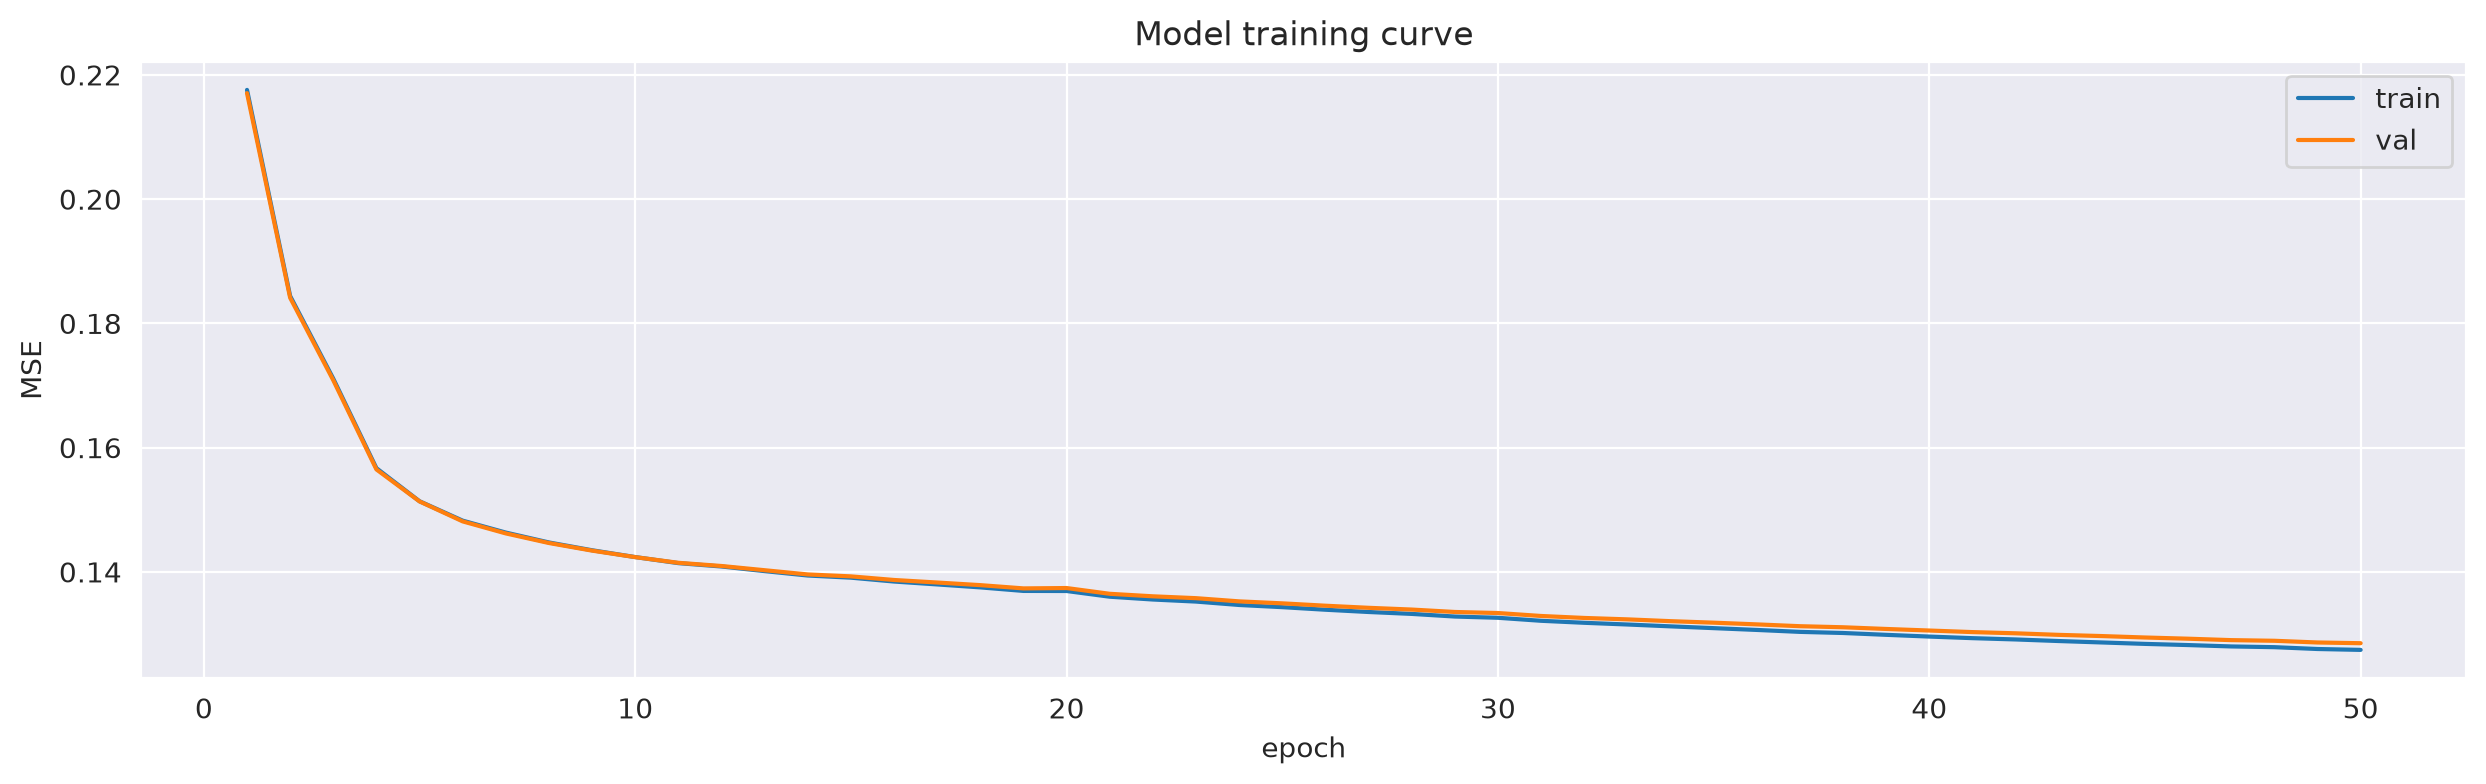

In [ ]:
df_hist = pl.DataFrame(history)

fig, ax = plt.subplots(figsize=(15, 4))
ax.plot(df_hist["epoch"], df_hist["train"], label="train")
ax.plot(df_hist["epoch"], df_hist["val"], label="val")
ax.set(xlabel="epoch", ylabel="MSE", title="Model training curve")
ax.legend()

In [ ]:
val_evaluator.run(loader_train)
print(f"train MSE: {val_evaluator.state.metrics['loss']:.4f}")

val_evaluator.run(loader_test)
print(f"test MSE for held-out donor: {val_evaluator.state.metrics['loss']:.4f}")

train MSE: 0.1274
test MSE for held-out donor: 0.1279


## Analysis

In [ ]:
model.eval()
with torch.no_grad():
    h_all = model(x_all.to(device))[0].cpu().numpy()

labels = ad.obs["label"].astype(str).to_numpy()
stim_idx = np.where(labels == "stim")[0]
ctrl_idx = np.where(labels == "ctrl")[0]

idx_stim_train = np.intersect1d(trainval_idx, stim_idx)
idx_ctrl_train = np.intersect1d(trainval_idx, ctrl_idx)
idx_stim_test = np.intersect1d(test_idx, stim_idx)
idx_ctrl_test = np.intersect1d(test_idx, ctrl_idx)

h_stim_train = h_all[idx_stim_train]
h_ctrl_train = h_all[idx_ctrl_train]
h_stim_test = h_all[idx_stim_test]
h_ctrl_test = h_all[idx_ctrl_test]

print(
    f"train: {len(h_stim_train)} stim, {len(h_ctrl_train)} ctrl | "
    f"test: {len(h_stim_test)} stim, {len(h_ctrl_test)} ctrl"
)

train: 11192 stim, 11457 ctrl | test: 1166 stim, 858 ctrl


In [ ]:
# interferon direction from training donors only
v = h_stim_train.mean(0) - h_ctrl_train.mean(0)

In [ ]:
v_t = torch.tensor(v, device=device, dtype=torch.float32)
with torch.no_grad():
    h_c = torch.tensor(h_ctrl_test, device=device)
    x_base = model.dec(h_c).cpu().numpy()  # decoded ctrl (before)
    x_steer = model.dec(h_c + v_t).cpu().numpy()  # decoded ctrl + v (after)

x_real_stim = x_all[idx_stim_test].numpy()  # real stimulated cells
ctypes = ad.obs["cell_type"].astype(str).to_numpy()
gene_names = ad.var_names.to_numpy()
isg_idx = np.where(np.isin(gene_names, genes_ISG))[0]

### Control cells after steering with interferon

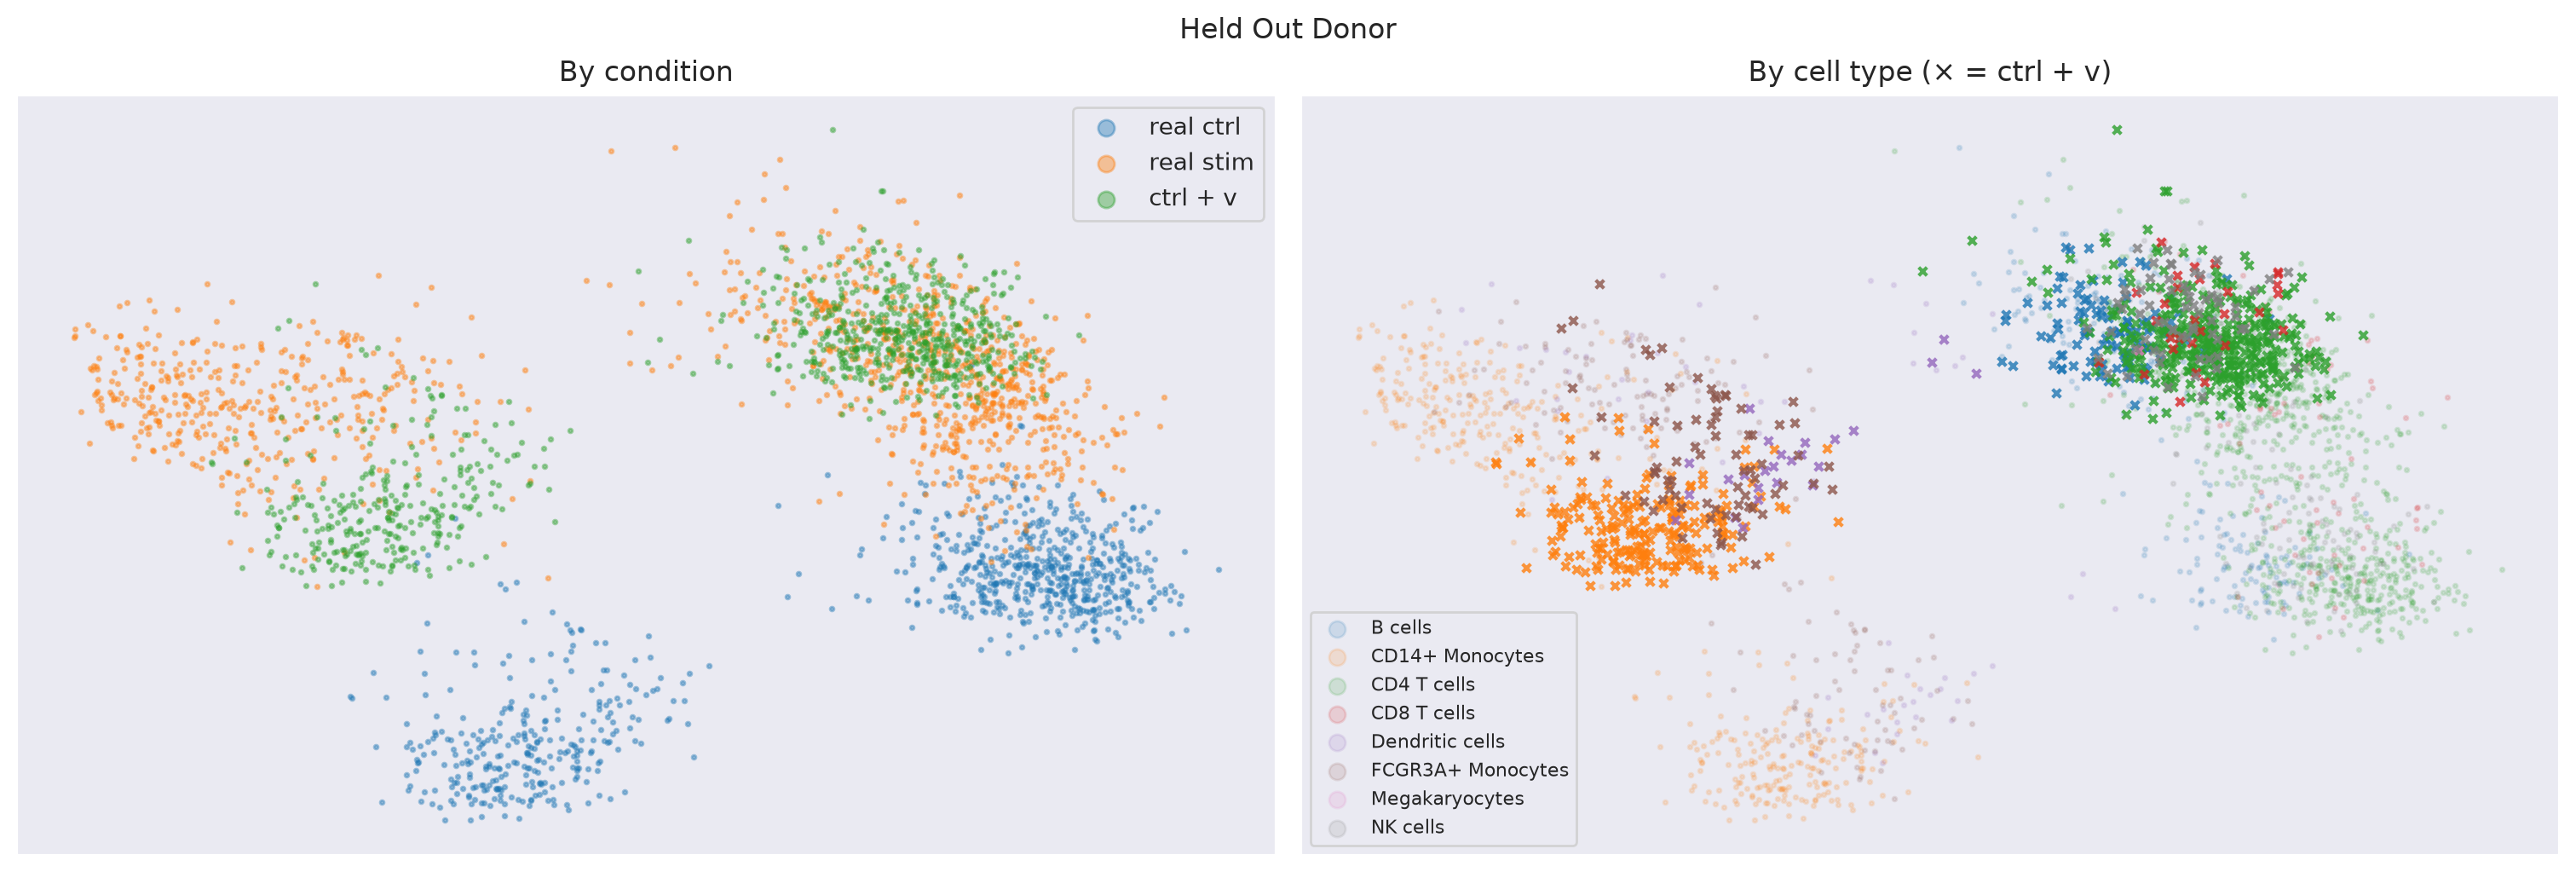

In [ ]:
def _():
    ct = ad.obs["cell_type"].astype(str).to_numpy()
    pca = sk.decomposition.PCA(n_components=2).fit(np.vstack([h_ctrl_test, h_stim_test]))

    groups = [
        ("real ctrl", pca.transform(h_ctrl_test), ct[idx_ctrl_test]),
        ("real stim", pca.transform(h_stim_test), ct[idx_stim_test]),
        ("ctrl + v", pca.transform(h_ctrl_test + v), ct[idx_ctrl_test]),
    ]
    types = sorted(np.unique(ct))
    colors = dict(zip(types, sns.color_palette("tab10", len(types))))

    fig, axes = plt.subplots(1, 2, figsize=(15, 5), constrained_layout=True)

    # by condition
    for name, p, _ in groups:
        axes[0].scatter(p[:, 0], p[:, 1], s=3, alpha=0.4, label=name)
    axes[0].legend(markerscale=4)
    axes[0].set(title="By condition", xticks=[], yticks=[])

    # by cell type (real ctrl/stim as faint dots, steered as crosses)
    for name, p, c in groups:
        for t in types:
            m = c == t
            if name == "ctrl + v":
                axes[1].scatter(p[m, 0], p[m, 1], s=12, marker="x", alpha=0.8, color=colors[t])
            else:
                axes[1].scatter(
                    p[m, 0],
                    p[m, 1],
                    s=3,
                    alpha=0.15,
                    color=colors[t],
                    label=t if name == "real ctrl" else None,
                )
    axes[1].legend(markerscale=4, fontsize=8)
    axes[1].set(title="By cell type (× = ctrl + v)", xticks=[], yticks=[])
    plt.suptitle("Held Out Donor")

    return fig

_()

### Average expression of the Interferon genes in each cell

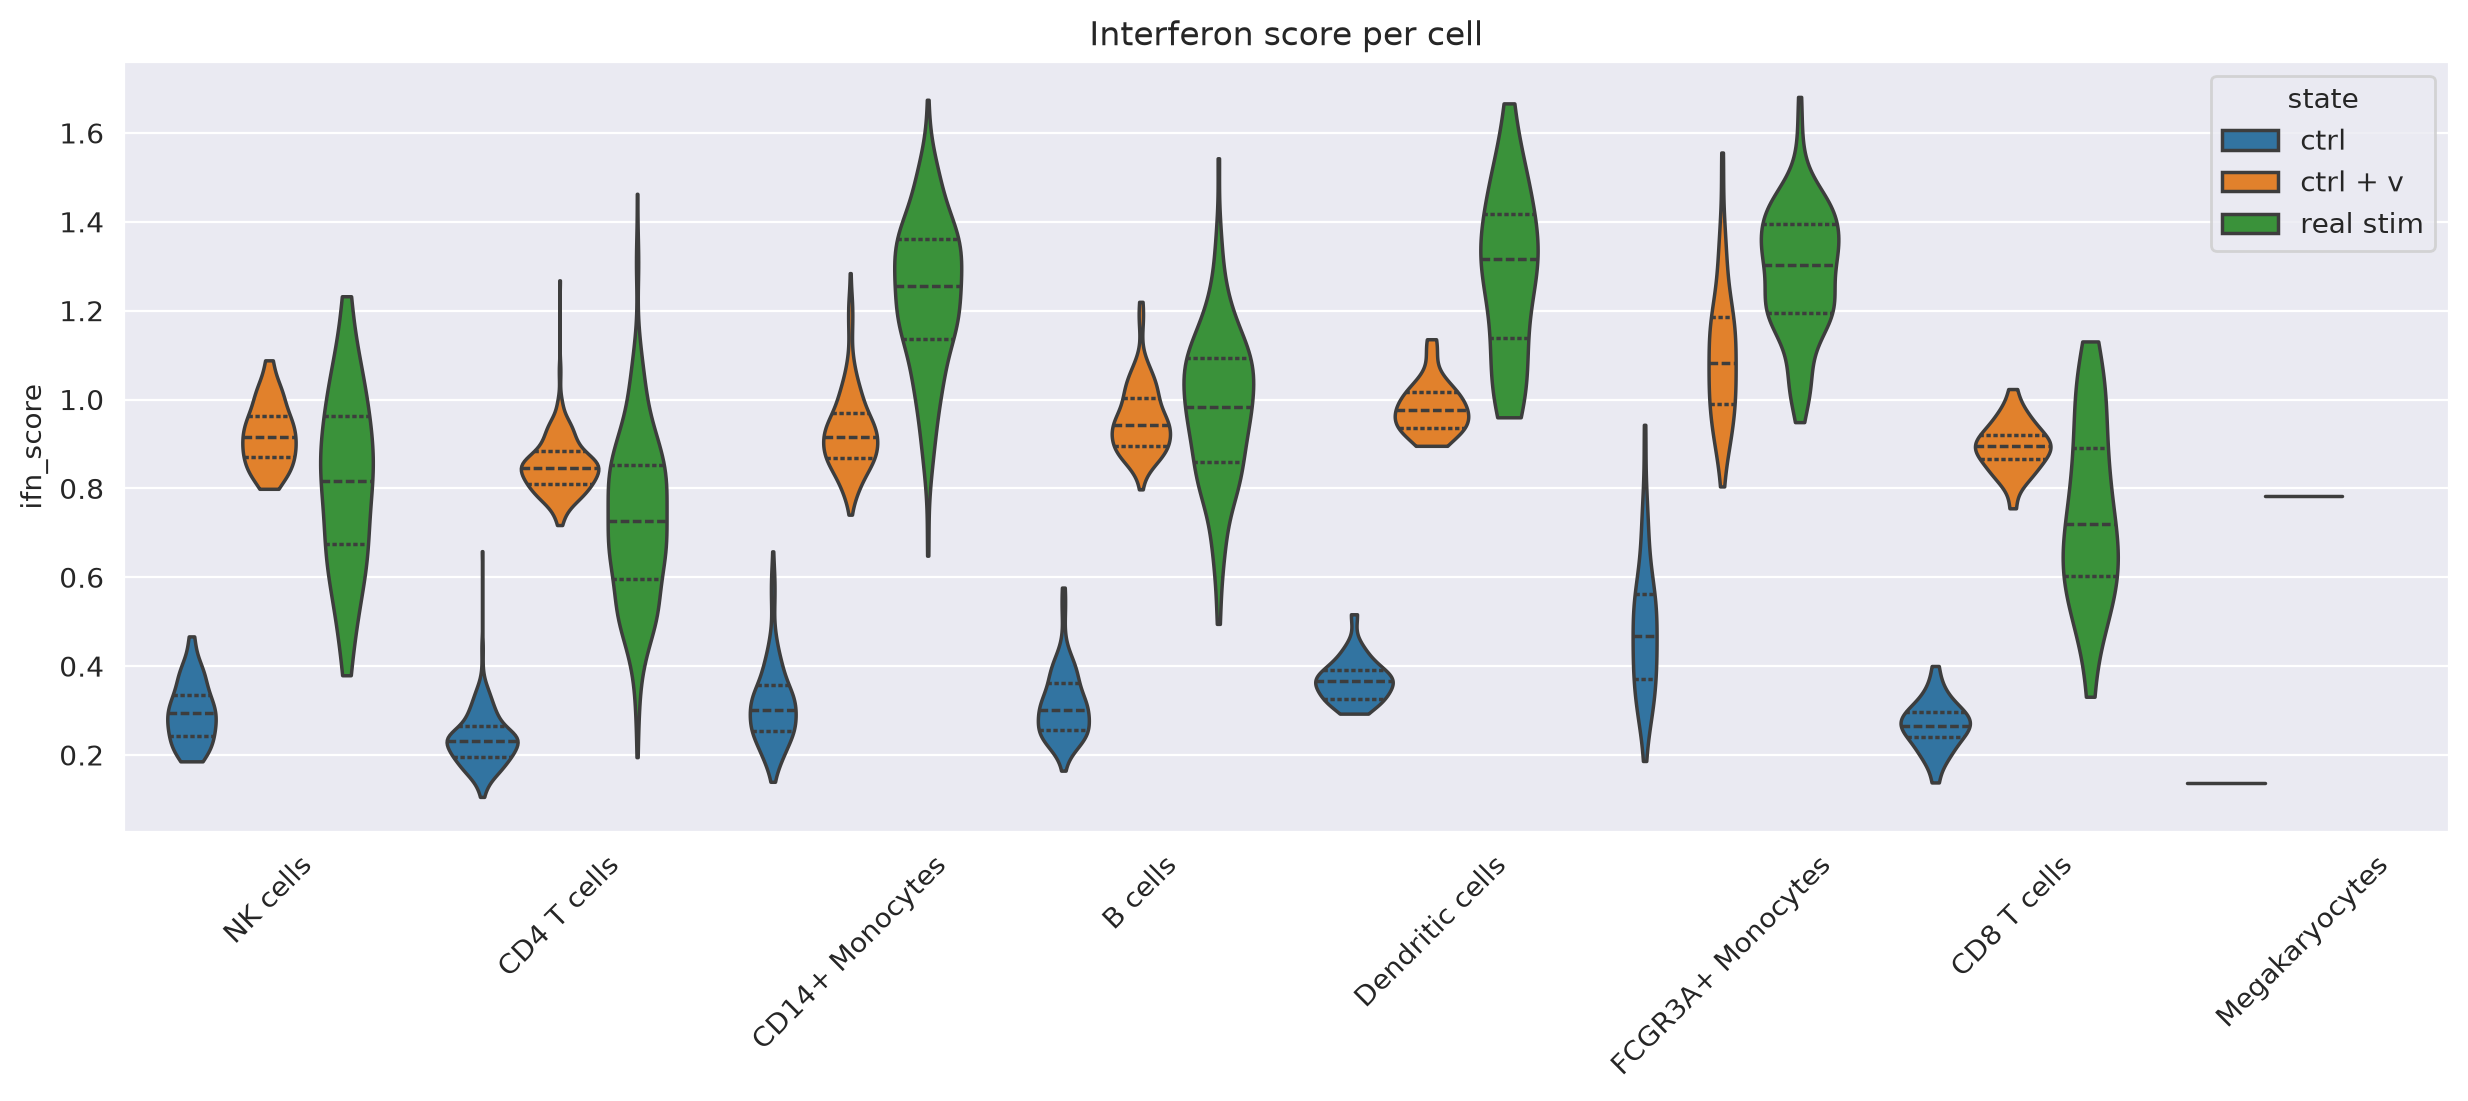

In [ ]:
def _():
    score = lambda M: M[:, isg_idx].mean(1)
    df = pl.concat(
        [
            pl.DataFrame(
                {
                    "cell_type": ctypes[idx_ctrl_test],
                    "state": "ctrl",
                    "ifn_score": score(x_base),
                }
            ),
            pl.DataFrame(
                {
                    "cell_type": ctypes[idx_ctrl_test],
                    "state": "ctrl + v",
                    "ifn_score": score(x_steer),
                }
            ),
            pl.DataFrame(
                {
                    "cell_type": ctypes[idx_stim_test],
                    "state": "real stim",
                    "ifn_score": score(x_real_stim),
                }
            ),
        ]
    )
    fig, ax = plt.subplots(figsize=(15, 5))
    sns.violinplot(
        df.to_pandas(),
        x="cell_type",
        y="ifn_score",
        hue="state",
        cut=0,
        inner="quartile",
        ax=ax,
    )
    ax.tick_params(axis="x", labelrotation=45)
    ax.set(xlabel="", title="Interferon score per cell")
    return fig

_()